<a href="https://colab.research.google.com/github/swatijaincts/GENAI-Course/blob/Colab-link/BERT_NSP_Next_Sentence_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🤖 Next Sentence Prediction (NSP) with BERT
### *A Beginner-Friendly Walkthrough*

---

Welcome! 👋 In this notebook, we'll learn about **Next Sentence Prediction (NSP)** — one of the two key tasks that BERT was trained on.

By the end of this notebook, you'll understand:
- 🧠 What BERT is (in plain English!)
- 🔗 What Next Sentence Prediction is and WHY it matters
- 🛠️ How to use BERT to actually predict if two sentences are related
- 📊 How to visualize and interpret the results

---

> 💡 **No experience needed!** We'll explain every concept before writing code.

## 📖 Chapter 1: What is BERT?

---

**BERT** stands for **B**idirectional **E**ncoder **R**epresentations from **T**ransformers.

That's a mouthful! Let's break it down with an analogy. 🎯

### 📚 Imagine BERT as a Student Who Read the Entire Internet

Before BERT can help you, it went to school — it read **billions of sentences** from the internet and learned how language works. It learned things like:
- Words that usually go together
- Sentences that usually follow each other
- The overall meaning and flow of text

### 🔄 The "Bidirectional" Part

Older language models only read text **left to right** (like how you normally read). BERT is special because it reads text in **BOTH directions** at the same time!

```
Old model:  I love eating  →→→→→→→→→→→→→→  pizza

BERT:       I love eating  ←←→→→→←←→→←→→→  pizza
                     (reads both ways!)
```

This means BERT understands **context** much better.

### 🎓 How Was BERT Trained?

BERT was trained on TWO tasks simultaneously:
1. **Masked Language Modeling (MLM)** — Fill in the blank (e.g., "I love eating [MASK]")
2. **Next Sentence Prediction (NSP)** — Do these two sentences naturally follow each other? ← *This is what we'll focus on!*

## 🔗 Chapter 2: What is Next Sentence Prediction?

---

### The Core Idea

Imagine you're reading a book, and someone shows you two sentences:

> **Sentence A:** *"The dog ran into the park."*
>
> **Sentence B:** *"It started chasing a ball happily."*

Does Sentence B logically follow Sentence A? **Yes!** 🐶⚽ That makes perfect sense.

Now try this:

> **Sentence A:** *"The dog ran into the park."*
>
> **Sentence B:** *"The stock market crashed in 1929."*

Does Sentence B follow Sentence A? **No!** 😅 These are completely unrelated.

---

### 🎯 This is Exactly What BERT's NSP Does!

During training, BERT was shown millions of sentence pairs and had to answer:
- **IsNextSentence** → These sentences are connected (50% of the time)
- **NotNextSentence** → These sentences are random / unrelated (50% of the time)

### 💼 Why Does This Matter in the Real World?

NSP helps BERT understand **relationships between sentences**, which is crucial for tasks like:
- 🔍 **Question Answering** — Finding the right paragraph that answers a question
- 💬 **Chatbots** — Generating relevant follow-up responses
- 📄 **Document Summarization** — Understanding how paragraphs connect
- 🕵️ **Information Retrieval** — Matching queries with relevant documents

---

Let's now see this in action with actual code! 🚀

## 🛠️ Chapter 3: Setting Up Our Environment

---

First, we need to install the libraries we'll use. Think of libraries as **pre-built tools** — instead of building a hammer from scratch, we just pick one up!

We'll use:
- 🤗 **Transformers** — Hugging Face's library that gives us easy access to BERT
- 🔢 **PyTorch** — The deep learning framework that BERT runs on
- 📊 **Matplotlib & Seaborn** — For beautiful visualizations

In [ ]:
# Install the required libraries
# The '!' tells Colab to run this as a terminal command
!pip install transformers torch -q

print(" Libraries installed successfully!")

 Libraries installed successfully!


In [ ]:
# Now let's import everything we need

import torch                          # The brain behind BERT
import torch.nn.functional as F       # For softmax (converting scores to probabilities)
import matplotlib.pyplot as plt       # For making charts
import matplotlib.patches as mpatches
import seaborn as sns                  # For prettier charts
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Transformers gives us BERT!
from transformers import BertTokenizer, BertForNextSentencePrediction

print(" All libraries imported!")
print("\n Here's what each does:")
print("   BertTokenizer   Converts our text into numbers BERT understands")
print("   BertForNextSentencePrediction  The BERT model with an NSP 'head' on top")

 All libraries imported!

 Here's what each does:
   BertTokenizer   Converts our text into numbers BERT understands
   BertForNextSentencePrediction  The BERT model with an NSP 'head' on top


## 🧩 Chapter 4: Understanding the BERT Pipeline

---

Before we load BERT, let's understand the **flow** of what's going to happen:

```
┌─────────────────────────────────────────────────────────┐
│                                                         │
│  1. RAW TEXT                                            │
│     "The dog ran into the park."                        │
│     "It started chasing a ball."                        │
│                  ↓                                      │
│  2. TOKENIZER (splits into tokens + adds special tags)  │
│     [CLS] The dog ran [SEP] It started chasing [SEP]   │
│                  ↓                                      │
│  3. NUMBERS (BERT only understands numbers!)            │
│     [101, 1996, 3899, 2743, 102, 2009, ...]            │
│                  ↓                                      │
│  4. BERT MODEL (processes the numbers)                  │
│                  ↓                                      │
│  5. OUTPUT SCORES → IsNext or NotNext?                  │
│                                                         │
└─────────────────────────────────────────────────────────┘
```

### 🏷️ Special Tokens — The Secret Sauce!

BERT uses **special tokens** that signal structure to the model:

| Token | Meaning | Purpose |
|-------|---------|----------|
| `[CLS]` | Classification | Always at the START. BERT uses this token's output to make its final prediction |
| `[SEP]` | Separator | Marks the END of each sentence — tells BERT "one sentence ends here" |

## 📥 Chapter 5: Loading BERT

---

We'll use `bert-base-uncased`:
- **base** → The smaller, faster version (there's also `bert-large`)
- **uncased** → BERT doesn't care about CAPS vs lowercase ("Dog" = "dog")


In [ ]:
print(" Loading BERT... (this downloads ~450MB the first time, be patient!)")
print("   Think of this as waking BERT up from a deep sleep \n")

# Load the tokenizer  converts words to numbers
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Load the BERT model configured for NSP
model = BertForNextSentencePrediction.from_pretrained('bert-base-uncased')

# Put model in evaluation mode (not training mode)
# This is important! In eval mode, BERT is just predicting, not learning.
model.eval()

print("\n BERT is awake and ready!")
print(f" Total parameters in BERT: {sum(p.numel() for p in model.parameters()):,}")
print("   (That's ~110 million numbers that BERT learned during training!)")

 Loading BERT... (this downloads ~450MB the first time, be patient!)
   Think of this as waking BERT up from a deep sleep 



tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForNextSentencePrediction LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 BERT is awake and ready!
 Total parameters in BERT: 109,483,778
   (That's ~110 million numbers that BERT learned during training!)


## 🔬 Chapter 6: Our First NSP Prediction!

---

Let's build a simple, reusable function that:
1. Takes two sentences as input
2. Feeds them to BERT
3. Returns a human-readable prediction with confidence scores

In [ ]:
def predict_next_sentence(sentence_a, sentence_b, verbose=True):
    """
    Predicts whether sentence_b is the natural next sentence after sentence_a.

    Args:
        sentence_a: The first sentence
        sentence_b: The candidate 'next' sentence
        verbose: If True, prints a detailed explanation

    Returns:
        A dict with label, confidence, and probabilities
    """

    #  STEP 1: Tokenize
    # The tokenizer automatically adds [CLS] and [SEP] tokens
    # and creates the 'token_type_ids' to tell BERT which sentence is which
    inputs = tokenizer(
        sentence_a,
        sentence_b,
        return_tensors='pt',   # 'pt' = PyTorch tensors
        padding=True,
        truncation=True,
        max_length=512         # BERT's max input length
    )

    #  STEP 2: Show what BERT sees (the tokens)
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

    #  STEP 3: Get BERT's prediction
    with torch.no_grad():   # no_grad = don't compute gradients (saves memory)
        outputs = model(**inputs)

    # outputs.logits has shape [1, 2]
    # Index 0 = IsNextSentence score
    # Index 1 = NotNextSentence score
    logits = outputs.logits

    #  STEP 4: Convert raw scores to probabilities (using softmax)
    # Softmax turns any numbers into probabilities that sum to 1 (= 100%)
    probs = F.softmax(logits, dim=1)[0]
    is_next_prob     = probs[0].item()
    not_next_prob    = probs[1].item()

    #  STEP 5: Make the decision
    prediction = "IsNext" if is_next_prob > not_next_prob else "NotNext"
    confidence = max(is_next_prob, not_next_prob) * 100

    #  STEP 6: Print a friendly explanation
    if verbose:
        print("" * 60)
        print(" INPUT SENTENCES")
        print(f"   Sentence A : {sentence_a}")
        print(f"   Sentence B : {sentence_b}")
        print()
        print(" WHAT BERT ACTUALLY SEES (Tokens):")
        print(f"   {' '.join(tokens)}")
        print()
        print(" BERT'S VERDICT")
        print(f"    IsNext probability    : {is_next_prob*100:.1f}%")
        print(f"    NotNext probability   : {not_next_prob*100:.1f}%")
        print()
        emoji = "" if prediction == "IsNext" else ""
        print(f"   {emoji} PREDICTION: '{prediction}' with {confidence:.1f}% confidence")
        print("" * 60)

    return {
        'label': prediction,
        'confidence': confidence,
        'is_next_prob': is_next_prob,
        'not_next_prob': not_next_prob,
        'tokens': tokens
    }

print(" Function defined! Let's try it out!")

 Function defined! Let's try it out!


### 🟢 Test 1: Sentences That ARE Related

In [ ]:
# Test with sentences that clearly follow each other
sentence_a = "She opened the refrigerator and looked inside."
sentence_b = "There was nothing left to eat, so she decided to order pizza."

result1 = predict_next_sentence(sentence_a, sentence_b)


 INPUT SENTENCES
   Sentence A : She opened the refrigerator and looked inside.
   Sentence B : There was nothing left to eat, so she decided to order pizza.

 WHAT BERT ACTUALLY SEES (Tokens):
   [CLS] she opened the refrigerator and looked inside . [SEP] there was nothing left to eat , so she decided to order pizza . [SEP]

 BERT'S VERDICT
    IsNext probability    : 100.0%
    NotNext probability   : 0.0%

    PREDICTION: 'IsNext' with 100.0% confidence



### 🔴 Test 2: Sentences That Are NOT Related

In [ ]:
# Test with sentences that are completely unrelated
sentence_a = "She opened the refrigerator and looked inside."
sentence_b = "The Great Wall of China was built over many centuries."

result2 = predict_next_sentence(sentence_a, sentence_b)


 INPUT SENTENCES
   Sentence A : She opened the refrigerator and looked inside.
   Sentence B : The Great Wall of China was built over many centuries.

 WHAT BERT ACTUALLY SEES (Tokens):
   [CLS] she opened the refrigerator and looked inside . [SEP] the great wall of china was built over many centuries . [SEP]

 BERT'S VERDICT
    IsNext probability    : 0.0%
    NotNext probability   : 100.0%

    PREDICTION: 'NotNext' with 100.0% confidence



## 📊 Chapter 7: Visualizing BERT's Thinking

---

Numbers are fine, but visuals help us understand better! Let's test multiple sentence pairs and visualize the results.

In [ ]:
# Let's test a variety of sentence pairs
test_pairs = [
    {
        "A": "Scientists discovered a new species of deep-sea fish.",
        "B": "The creature was found at a depth of 3,000 meters.",
        "expected": "IsNext"
    },
    {
        "A": "The economy grew at a record pace this quarter.",
        "B": "My cat loves sleeping on warm blankets.",
        "expected": "NotNext"
    },
    {
        "A": "He trained for months before the marathon.",
        "B": "On race day, he finished in under four hours.",
        "expected": "IsNext"
    },
    {
        "A": "The recipe calls for two cups of flour.",
        "B": "Jupiter is the largest planet in our solar system.",
        "expected": "NotNext"
    },
    {
        "A": "The storm knocked out power across the city.",
        "B": "Thousands of residents were left without electricity overnight.",
        "expected": "IsNext"
    },
    {
        "A": "She graduated with honors from medical school.",
        "B": "The train was delayed by fifteen minutes.",
        "expected": "NotNext"
    },
]

# Run predictions on all pairs (silently)
results = []
for pair in test_pairs:
    r = predict_next_sentence(pair["A"], pair["B"], verbose=False)
    results.append({
        "pair_short": f"A: {pair['A'][:35]}...",
        "IsNext%": r['is_next_prob'] * 100,
        "NotNext%": r['not_next_prob'] * 100,
        "prediction": r['label'],
        "expected": pair['expected'],
        "correct": r['label'] == pair['expected']
    })

print(" All predictions done! Generating visualization...")

 All predictions done! Generating visualization...


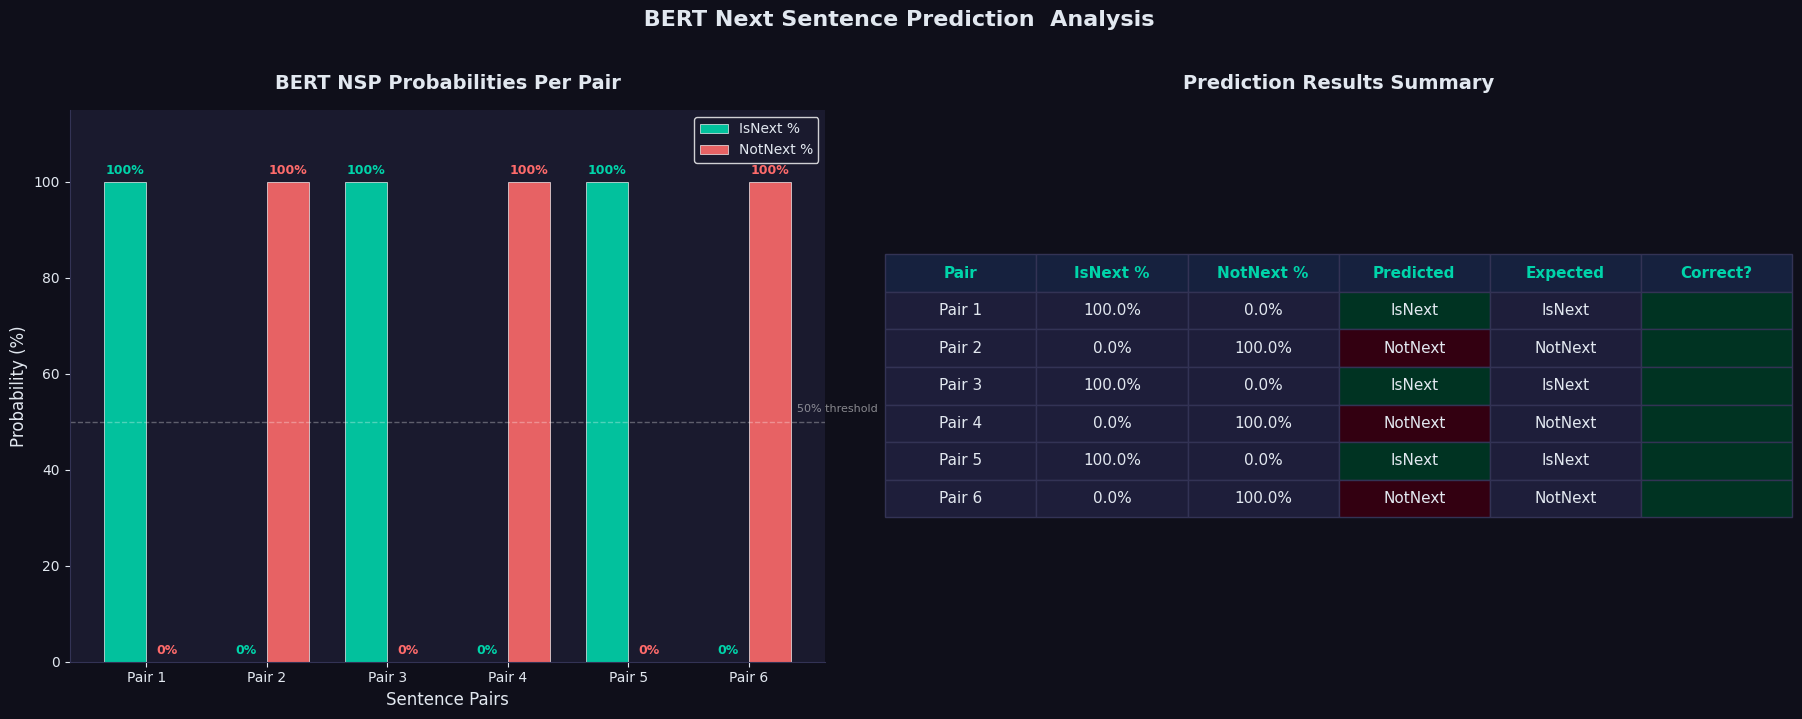

 Visualization complete!


In [ ]:
#  Visualization

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor('#0f0f1a')

# Color palette
TEAL   = '#00d4aa'
CORAL  = '#ff6b6b'
PURPLE = '#8b5cf6'
BG     = '#0f0f1a'
CARD   = '#1a1a2e'
TEXT   = '#e2e8f0'

#  Chart 1: Probability bars
ax1 = axes[0]
ax1.set_facecolor(CARD)

labels = [f"Pair {i+1}" for i in range(len(results))]
is_next_probs  = [r['IsNext%'] for r in results]
not_next_probs = [r['NotNext%'] for r in results]

x = np.arange(len(labels))
width = 0.35

bars1 = ax1.bar(x - width/2, is_next_probs,  width, label='IsNext %',  color=TEAL,  alpha=0.9, edgecolor='white', linewidth=0.5)
bars2 = ax1.bar(x + width/2, not_next_probs, width, label='NotNext %', color=CORAL, alpha=0.9, edgecolor='white', linewidth=0.5)

# Add value labels on bars
for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{bar.get_height():.0f}%', ha='center', va='bottom',
             color=TEAL, fontsize=9, fontweight='bold')
for bar in bars2:
    ax1.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
             f'{bar.get_height():.0f}%', ha='center', va='bottom',
             color=CORAL, fontsize=9, fontweight='bold')

ax1.set_xlabel('Sentence Pairs', color=TEXT, fontsize=12)
ax1.set_ylabel('Probability (%)', color=TEXT, fontsize=12)
ax1.set_title('BERT NSP Probabilities Per Pair', color=TEXT, fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, color=TEXT)
ax1.tick_params(colors=TEXT)
ax1.set_ylim(0, 115)
ax1.axhline(y=50, color='white', linestyle='--', alpha=0.3, linewidth=1)
ax1.text(5.4, 52, '50% threshold', color='white', alpha=0.5, fontsize=8)
ax1.legend(facecolor=CARD, edgecolor='white', labelcolor=TEXT)
ax1.spines['bottom'].set_color('#333355')
ax1.spines['left'].set_color('#333355')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
for tick in ax1.get_xticklabels() + ax1.get_yticklabels():
    tick.set_color(TEXT)

#  Chart 2: Results summary table
ax2 = axes[1]
ax2.set_facecolor(CARD)
ax2.axis('off')

col_labels = ['Pair', 'IsNext %', 'NotNext %', 'Predicted', 'Expected', 'Correct?']
table_data = []
cell_colors = []

for i, r in enumerate(results):
    row = [
        f"Pair {i+1}",
        f"{r['IsNext%']:.1f}%",
        f"{r['NotNext%']:.1f}%",
        r['prediction'],
        r['expected'],
        '' if r['correct'] else ''
    ]
    table_data.append(row)

    row_color = ['#1e1e3a'] * 6
    row_color[3] = '#003322' if r['prediction'] == 'IsNext' else '#330011'
    row_color[5] = '#003322' if r['correct'] else '#330011'
    cell_colors.append(row_color)

table = ax2.table(
    cellText=table_data,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    cellColours=cell_colors
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2.2)

# Style table
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#333355')
    if row == 0:
        cell.set_facecolor('#16213e')
        cell.set_text_props(color=TEAL, fontweight='bold')
    else:
        cell.set_text_props(color=TEXT)

ax2.set_title('Prediction Results Summary', color=TEXT, fontsize=14, fontweight='bold', pad=15)

#  Main title
fig.suptitle(' BERT Next Sentence Prediction  Analysis', color=TEXT,
             fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig('nsp_results.png', dpi=150, bbox_inches='tight',
            facecolor=BG, edgecolor='none')
plt.show()
print(" Visualization complete!")

## 🔍 Chapter 8: Looking Under the Hood — Tokenization

---

Let's take a deeper look at **what BERT actually sees** when we feed it text. Understanding tokenization is key to understanding BERT!

In [ ]:
def visualize_tokenization(sentence_a, sentence_b):
    """
    Shows step-by-step how BERT tokenizes two sentences.
    """
    inputs = tokenizer(
        sentence_a, sentence_b,
        return_tensors='pt',
        padding=True, truncation=True
    )

    tokens    = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    input_ids = inputs['input_ids'][0].tolist()
    seg_ids   = inputs['token_type_ids'][0].tolist()  # 0 = Sentence A, 1 = Sentence B

    print("" * 65)
    print(" TOKENIZATION DEEP DIVE")
    print("" * 65)
    print(f"\n Sentence A : '{sentence_a}'")
    print(f" Sentence B : '{sentence_b}'")
    print()
    print("")
    print("  Token            Token ID    Segment    Meaning     ")
    print("")

    for token, tid, seg in zip(tokens, input_ids, seg_ids):
        segment_label = "Sentence A" if seg == 0 else "Sentence B"

        if token == '[CLS]':
            meaning = " START"
        elif token == '[SEP]':
            meaning = "  SEPARATOR"
        elif token.startswith('##'):
            meaning = " subword"
        else:
            meaning = " word"

        print(f"  {token:<15}    {tid:<8}    {segment_label:<10}  {meaning:<12}")

    print("")
    print()
    print(" NOTES:")
    print("    [CLS] = Classification token. BERT's final prediction comes from this!")
    print("    [SEP] = Separator token. Marks the boundary between sentences.")
    print("    ## = Subword token. BERT splits unknown words into smaller pieces.")
    print(f"\n Total tokens: {len(tokens)} (BERT's limit is 512)")

# Try it!
visualize_tokenization(
    "Albert Einstein was a theoretical physicist.",
    "He developed the theory of relativity."
)


 TOKENIZATION DEEP DIVE


 Sentence A : 'Albert Einstein was a theoretical physicist.'
 Sentence B : 'He developed the theory of relativity.'


  Token            Token ID    Segment    Meaning     

  [CLS]              101         Sentence A   START      
  albert             4789        Sentence A   word       
  einstein           15313       Sentence A   word       
  was                2001        Sentence A   word       
  a                  1037        Sentence A   word       
  theoretical        9373        Sentence A   word       
  physicist          13702       Sentence A   word       
  .                  1012        Sentence A   word       
  [SEP]              102         Sentence A    SEPARATOR 
  he                 2002        Sentence B   word       
  developed          2764        Sentence B   word       
  the                1996        Sentence B   word       
  theory             3399        Sentence B   word       
  of                 1997        Sentence B  

## 🎯 Chapter 9: Edge Cases — Where Does BERT Struggle?

---

BERT is powerful but not perfect. Let's test some tricky sentence pairs to see where it might struggle!

In [ ]:
print(" EDGE CASE EXPLORATION")
print("Let's see how BERT handles tricky sentences!\n")

edge_cases = [
    {
        "title": " Same Topic, But Random Fact (Tricky!)",
        "A": "Dogs are popular pets around the world.",
        "B": "The lifespan of a domestic dog is 10 to 13 years.",
        "note": "Related topic, but B doesn't necessarily 'follow' A  it's a separate fact."
    },
    {
        "title": " Contradictory Sentences",
        "A": "The weather was sunny and warm.",
        "B": "It was a dark and stormy night.",
        "note": "Do contradictions get flagged as NotNext?"
    },
    {
        "title": " Numbers and Facts",
        "A": "The population of the city is 2 million people.",
        "B": "This makes it the fifth largest city in the country.",
        "note": "B references A's number  should be IsNext."
    },
    {
        "title": " Humor / Non-sequitur",
        "A": "Why did the chicken cross the road?",
        "B": "To get to the other side!",
        "note": "Classic joke  does BERT understand jokes?"
    },
]

for case in edge_cases:
    print(f"\n{case['title']}")
    print(f" Note: {case['note']}")
    predict_next_sentence(case['A'], case['B'])

 EDGE CASE EXPLORATION
Let's see how BERT handles tricky sentences!


 Same Topic, But Random Fact (Tricky!)
 Note: Related topic, but B doesn't necessarily 'follow' A  it's a separate fact.

 INPUT SENTENCES
   Sentence A : Dogs are popular pets around the world.
   Sentence B : The lifespan of a domestic dog is 10 to 13 years.

 WHAT BERT ACTUALLY SEES (Tokens):
   [CLS] dogs are popular pets around the world . [SEP] the lifespan of a domestic dog is 10 to 13 years . [SEP]

 BERT'S VERDICT
    IsNext probability    : 100.0%
    NotNext probability   : 0.0%

    PREDICTION: 'IsNext' with 100.0% confidence


 Contradictory Sentences
 Note: Do contradictions get flagged as NotNext?

 INPUT SENTENCES
   Sentence A : The weather was sunny and warm.
   Sentence B : It was a dark and stormy night.

 WHAT BERT ACTUALLY SEES (Tokens):
   [CLS] the weather was sunny and warm . [SEP] it was a dark and stormy night . [SEP]

 BERT'S VERDICT
    IsNext probability    : 100.0%
    NotNext probabili

## 🎮 Chapter 10: Try It Yourself!

---

Now it's **your turn**! Modify the sentences below and run the cell to test your own pairs.

 Running YOUR custom prediction...


 INPUT SENTENCES
   Sentence A : The astronaut floated weightlessly in the spacecraft.
   Sentence B : She looked out the window and saw the Earth below.

 WHAT BERT ACTUALLY SEES (Tokens):
   [CLS] the astronaut floated weight ##lessly in the spacecraft . [SEP] she looked out the window and saw the earth below . [SEP]

 BERT'S VERDICT
    IsNext probability    : 100.0%
    NotNext probability   : 0.0%

    PREDICTION: 'IsNext' with 100.0% confidence



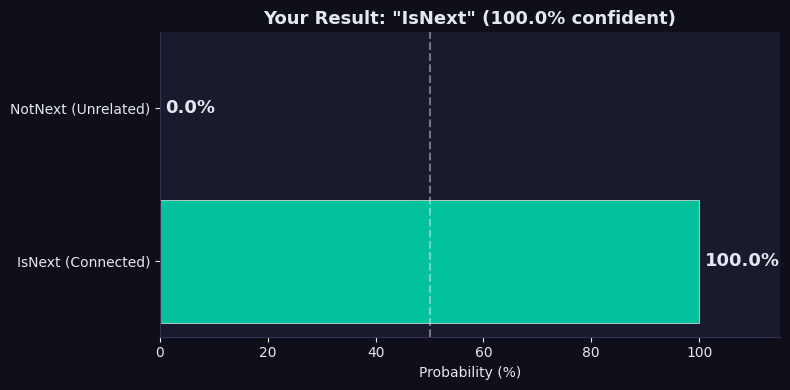

In [ ]:
#  EDIT THESE TWO SENTENCES AND RUN THE CELL!
#

MY_SENTENCE_A = "The astronaut floated weightlessly in the spacecraft."
MY_SENTENCE_B = "She looked out the window and saw the Earth below."

#
# Don't change anything below this line!

print(" Running YOUR custom prediction...\n")
my_result = predict_next_sentence(MY_SENTENCE_A, MY_SENTENCE_B)

# Quick bar chart for your result
fig, ax = plt.subplots(figsize=(8, 4))
fig.patch.set_facecolor('#0f0f1a')
ax.set_facecolor('#1a1a2e')

categories = ['IsNext (Connected)', 'NotNext (Unrelated)']
values = [my_result['is_next_prob']*100, my_result['not_next_prob']*100]
colors = ['#00d4aa', '#ff6b6b']

bars = ax.barh(categories, values, color=colors, alpha=0.9, edgecolor='white', linewidth=0.5)

for bar, val in zip(bars, values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', color='#e2e8f0', fontsize=13, fontweight='bold')

ax.set_xlim(0, 115)
ax.axvline(x=50, color='white', linestyle='--', alpha=0.4)
ax.set_xlabel('Probability (%)', color='#e2e8f0')
ax.set_title(f'Your Result: "{my_result["label"]}" ({my_result["confidence"]:.1f}% confident)',
             color='#e2e8f0', fontsize=13, fontweight='bold')
ax.tick_params(colors='#e2e8f0')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color('#333355')
ax.spines['left'].set_color('#333355')
for tick in ax.get_yticklabels():
    tick.set_color('#e2e8f0')

plt.tight_layout()
plt.show()

## Chapter 11: Training BERT for Next Sentence Prediction

---

The earlier chapters used a pretrained BERT model to perform Next Sentence Prediction (NSP). In this section, we will actually train the NSP task.

We will use the **WikiText-2** corpus to create sentence pairs. The dataset contains Wikipedia text and is suitable for constructing positive and negative sentence pairs.

The training objective is:

- Label `0`: Sentence B is the actual next sentence after Sentence A.
- Label `1`: Sentence B is a randomly selected sentence and is not the actual next sentence.

This section is specifically about **Next Sentence Prediction**. It does not train a Question Answering model.

### Important note about the model

The original BERT paper trained NSP jointly with Masked Language Modeling during pretraining. Here we isolate NSP so that the notebook can clearly demonstrate the task by itself.

We will start from pretrained `bert-base-uncased` weights and fine-tune the NSP classification head and BERT parameters on sentence-pair examples.

In [ ]:
import random
import numpy as np
import torch
from datasets import load_dataset, Dataset
from torch.utils.data import DataLoader
from transformers import (
    BertTokenizer,
    BertForNextSentencePrediction,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Chapter 12: Load WikiText-2 and Build NSP Examples

---

For NSP, we need consecutive sentences. WikiText is organized as lines of Wikipedia text, so we first clean the corpus and split paragraphs into sentences.

A positive example contains two consecutive sentences from the same paragraph. A negative example keeps Sentence A but replaces Sentence B with a sentence sampled from another location.

In [ ]:
# !pip install --upgrade datasets huggingface_hub -q

# raw_wikitext = load_dataset("wikitext", "wikitext-2-raw-v1")

from datasets import load_dataset

raw_wikitext = load_dataset(  # try the same for dxatsets like wikitext2 , wikitext 103 , PenTreebank , Tiny Shakespare etc
    "Salesforce/wikitext",
    "wikitext-2-raw-v1"
)

print(raw_wikitext)
print(raw_wikitext["train"][0])

print(raw_wikitext)
print(raw_wikitext["train"][0])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
{'text': ''}
DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
{'text': ''}


In [ ]:
import re

def split_into_sentences(text):
    text = re.sub(r"\\s+", " ", text).strip()
    if not text:
        return []
    sentences = re.split(r"(?<=[.!?])\\s+", text)
    return [s.strip() for s in sentences if len(s.strip().split()) >= 3]

def extract_paragraphs(split):
    paragraphs = []
    current = []

    for row in raw_wikitext[split]:
        text = row["text"].strip()

        if not text:
            if current:
                paragraphs.append(current)
                current = []
            continue

        if text.startswith("=") and text.endswith("="):
            continue

        sentences = split_into_sentences(text)
        current.extend(sentences)

    if current:
        paragraphs.append(current)

    return [p for p in paragraphs if len(p) >= 2]

train_paragraphs = extract_paragraphs("train")
validation_paragraphs = extract_paragraphs("validation")

print("Training paragraphs:", len(train_paragraphs))
print("Validation paragraphs:", len(validation_paragraphs))
print("Example paragraph:")
print(train_paragraphs[0][:3])

Training paragraphs: 4149
Validation paragraphs: 408
Example paragraph:
['Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " .', "The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard features of the series , it also underwent multiple adjustments , such as ma

In [ ]:
def build_nsp_examples(paragraphs, num_examples, seed=42):
    rng = random.Random(seed)
    all_sentences = [s for p in paragraphs for s in p]
    examples = []

    for _ in range(num_examples // 2):
        paragraph = rng.choice(paragraphs)
        index = rng.randrange(len(paragraph) - 1)

        sentence_a = paragraph[index]
        sentence_b = paragraph[index + 1]

        examples.append({
            "sentence_a": sentence_a,
            "sentence_b": sentence_b,
            "label": 0,
        })

        negative_b = rng.choice(all_sentences)
        attempts = 0
        while negative_b == sentence_b and attempts < 10:
            negative_b = rng.choice(all_sentences)
            attempts += 1

        examples.append({
            "sentence_a": sentence_a,
            "sentence_b": negative_b,
            "label": 1,
        })

    rng.shuffle(examples)
    return examples

TRAIN_EXAMPLES = 4000
VALIDATION_EXAMPLES = 800

train_examples = build_nsp_examples(
    train_paragraphs,
    TRAIN_EXAMPLES,
    seed=SEED,
)

validation_examples = build_nsp_examples(
    validation_paragraphs,
    VALIDATION_EXAMPLES,
    seed=SEED + 1,
)

print("Training examples:", len(train_examples))
print("Validation examples:", len(validation_examples))
print("\nExample positive pair:")
for example in train_examples:
    if example["label"] == 0:
        print("Sentence A:", example["sentence_a"])
        print("Sentence B:", example["sentence_b"])
        print("Label:", example["label"], "(IsNext)")
        break

print("\nExample negative pair:")
for example in train_examples:
    if example["label"] == 1:
        print("Sentence A:", example["sentence_a"])
        print("Sentence B:", example["sentence_b"])
        print("Label:", example["label"], "(NotNext)")
        break

Training examples: 4000
Validation examples: 800

Example positive pair:
Sentence A: With the growth of telecommuting , many men are also able to work from home . In this regard , he is contributing financially to the family while also acting as the primary caregiver of the family 's children . Differences in parent 's schedules can also account for some of the stay @-@ at @-@ home dads . Sometimes the father works odd work shifts while the mother has a typical nine @-@ to @-@ five work schedule .
Sentence B: Fixed gender roles began to become less prominent in the Western world starting in the late 20th century , allowing men to make their own choice of career without regard to traditional gender @-@ based roles . Some men who choose this role may do so because they enjoy being an active part of their children 's lives , while in other families , the mother wants to pursue her career . For example , of the 187 participants at Fortune Magazine 's Most Powerful Women in the Business Sum

## Chapter 13: Tokenize the Sentence Pairs

---

BERT receives the pair as:

```text
[CLS] Sentence A [SEP] Sentence B [SEP]
```

The tokenizer also creates `token_type_ids`, where `0` identifies Sentence A and `1` identifies Sentence B.

In [ ]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

train_dataset = Dataset.from_list(train_examples)
validation_dataset = Dataset.from_list(validation_examples)

def tokenize_nsp(batch):
    encoded = tokenizer(
        batch["sentence_a"],
        batch["sentence_b"],
        truncation=True,
        max_length=128,
    )
    encoded["labels"] = batch["label"]
    return encoded

train_tokenized = train_dataset.map(
    tokenize_nsp,
    batched=True,
    remove_columns=train_dataset.column_names,
)

validation_tokenized = validation_dataset.map(
    tokenize_nsp,
    batched=True,
    remove_columns=validation_dataset.column_names,
)

print(train_tokenized)
print(train_tokenized[0].keys())

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 4000
})
dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])


In [ ]:
sample = train_tokenized[0]
tokens = tokenizer.convert_ids_to_tokens(sample["input_ids"])

print("Tokens:")
print(tokens)
print("\nToken type IDs:")
print(sample["token_type_ids"])
print("\nLabel:", sample["labels"])
print("Label meaning:", "IsNext" if sample["labels"] == 0 else "NotNext")

Tokens:
['[CLS]', 'with', 'the', 'growth', 'of', 'telecom', '##mut', '##ing', ',', 'many', 'men', 'are', 'also', 'able', 'to', 'work', 'from', 'home', '.', 'in', 'this', 'regard', ',', 'he', 'is', 'contributing', 'financially', 'to', 'the', 'family', 'while', 'also', 'acting', 'as', 'the', 'primary', 'care', '##gi', '##ver', 'of', 'the', 'family', "'", 's', 'children', '.', 'differences', 'in', 'parent', "'", 's', 'schedules', 'can', 'also', 'account', 'for', 'some', 'of', 'the', 'stay', '@', '-', '@', '[SEP]', 'fixed', 'gender', 'roles', 'began', 'to', 'become', 'less', 'prominent', 'in', 'the', 'western', 'world', 'starting', 'in', 'the', 'late', '20th', 'century', ',', 'allowing', 'men', 'to', 'make', 'their', 'own', 'choice', 'of', 'career', 'without', 'regard', 'to', 'traditional', 'gender', '@', '-', '@', 'based', 'roles', '.', 'some', 'men', 'who', 'choose', 'this', 'role', 'may', 'do', 'so', 'because', 'they', 'enjoy', 'being', 'an', 'active', 'part', 'of', 'their', 'children',

## Chapter 14: Load the NSP Model

---

`BertForNextSentencePrediction` contains the pretrained BERT encoder plus a two-class NSP head.

The two output classes are:

- Class `0`: IsNext
- Class `1`: NotNext

In [ ]:
qa_model = None

nsp_model = BertForNextSentencePrediction.from_pretrained(
    "bert-base-uncased"
)
nsp_model.to(device)

print("Model loaded.")
print("Total parameters:", sum(p.numel() for p in nsp_model.parameters()))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] BertForNextSentencePrediction LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded.
Total parameters: 109483778


## Chapter 15: Train BERT on Next Sentence Prediction

---

We will use a small configurable dataset so the notebook can run on a Colab GPU. Increase `TRAIN_EXAMPLES`, `EPOCHS`, or the batch size when more compute is available.

In [ ]:
BATCH_SIZE = 8  # do the same for different batch sizes , epochs , learning rate and plot the accuracy
EPOCHS = 10
LEARNING_RATE = 2e-5

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

train_loader = DataLoader(
    train_tokenized,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator,
)

validation_loader = DataLoader(
    validation_tokenized,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
)

optimizer = torch.optim.AdamW(
    nsp_model.parameters(),
    lr=LEARNING_RATE,
)

#loss_fn = nn.CrossEntropyLoss()     do the same for losses like weighted cross entropy , focal loss etc

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)

print("Training batches per epoch:", len(train_loader))
print("Total training steps:", total_steps)

Training batches per epoch: 500
Total training steps: 5000


In [ ]:
def evaluate_nsp(model, loader):
    model.eval()
    total_loss = 0.0
    predictions = []
    labels = []

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)

            total_loss += outputs.loss.item()
            predictions.extend(torch.argmax(outputs.logits, dim=1).cpu().tolist())
            labels.extend(batch["labels"].cpu().tolist())

    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(labels, predictions)
    return avg_loss, accuracy, predictions, labels


train_losses = []
validation_losses = []
validation_accuracies = []

for epoch in range(EPOCHS):
    nsp_model.train()
    running_loss = 0.0

    for step, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(device) for k, v in batch.items()}

        optimizer.zero_grad()
        outputs = nsp_model(**batch)
        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(nsp_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        running_loss += loss.item()

        if step % 100 == 0 or step == len(train_loader):
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Step {step}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    epoch_train_loss = running_loss / len(train_loader)
    val_loss, val_accuracy, _, _ = evaluate_nsp(nsp_model, validation_loader)

    train_losses.append(epoch_train_loss)
    validation_losses.append(val_loss)
    validation_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1} complete | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

Epoch 1/10 | Step 100/500 | Loss: 0.0000
Epoch 1/10 | Step 200/500 | Loss: 0.0000
Epoch 1/10 | Step 300/500 | Loss: 0.0000
Epoch 1/10 | Step 400/500 | Loss: 0.0000
Epoch 1/10 | Step 500/500 | Loss: 0.0000
Epoch 1 complete | Train Loss: 0.0084 | Validation Loss: 0.3115 | Validation Accuracy: 0.9700
Epoch 2/10 | Step 100/500 | Loss: 0.0001
Epoch 2/10 | Step 200/500 | Loss: 0.0003
Epoch 2/10 | Step 300/500 | Loss: 0.0000
Epoch 2/10 | Step 400/500 | Loss: 0.0016
Epoch 2/10 | Step 500/500 | Loss: 0.0000
Epoch 2 complete | Train Loss: 0.0401 | Validation Loss: 0.2105 | Validation Accuracy: 0.9712
Epoch 3/10 | Step 100/500 | Loss: 0.0000
Epoch 3/10 | Step 200/500 | Loss: 0.0000
Epoch 3/10 | Step 300/500 | Loss: 0.0000
Epoch 3/10 | Step 400/500 | Loss: 0.0000
Epoch 3/10 | Step 500/500 | Loss: 0.0000
Epoch 3 complete | Train Loss: 0.0059 | Validation Loss: 0.2096 | Validation Accuracy: 0.9750
Epoch 4/10 | Step 100/500 | Loss: 0.0000
Epoch 4/10 | Step 200/500 | Loss: 0.0000
Epoch 4/10 | Step 300

## Chapter 16: Evaluate the Trained NSP Model

In [ ]:
val_loss, val_accuracy, predictions, labels = evaluate_nsp(
    nsp_model,
    validation_loader,
)

print("Validation loss:", round(val_loss, 4))
print("Validation accuracy:", round(val_accuracy, 4))
print("\nClassification report:")
print(
    classification_report(
        labels,
        predictions,
        target_names=["IsNext", "NotNext"],
        digits=4,
    )
)

Validation loss: 0.2411
Validation accuracy: 0.9775

Classification report:
              precision    recall  f1-score   support

      IsNext     0.9751    0.9800    0.9776       400
     NotNext     0.9799    0.9750    0.9774       400

    accuracy                         0.9775       800
   macro avg     0.9775    0.9775    0.9775       800
weighted avg     0.9775    0.9775    0.9775       800



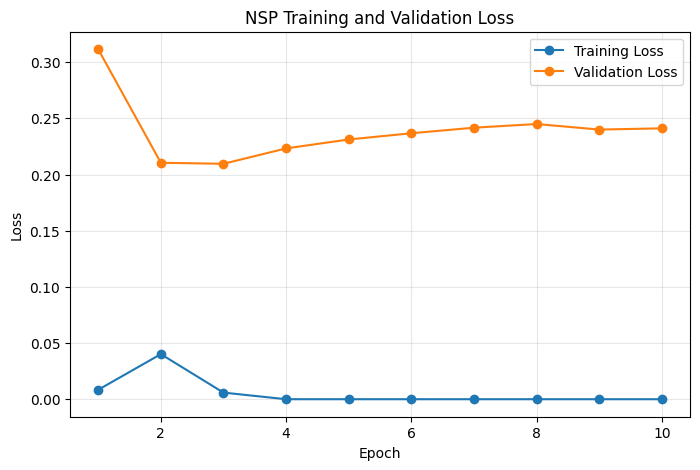

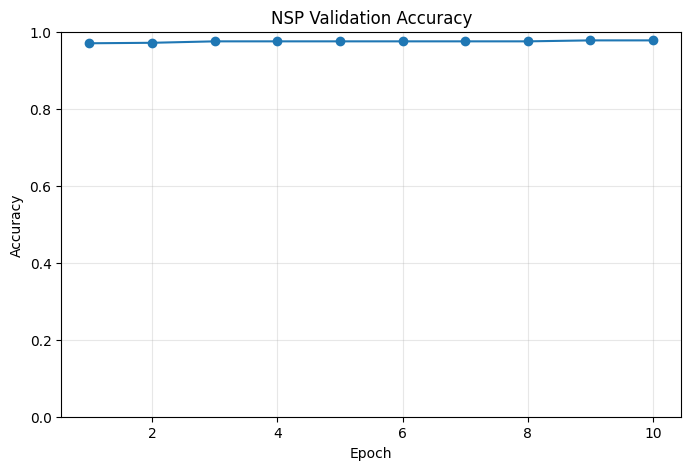

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, marker="o", label="Training Loss")
plt.plot(range(1, EPOCHS + 1), validation_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("NSP Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), validation_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("NSP Validation Accuracy")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.show()

## Chapter 17: Test the Fine-Tuned NSP Model

---

The following function uses the fine-tuned model instead of the original pretrained NSP model.

In [ ]:
def predict_trained_nsp(sentence_a, sentence_b, verbose=True):
    nsp_model.eval()

    inputs = tokenizer(
        sentence_a,
        sentence_b,
        return_tensors="pt",
        truncation=True,
        max_length=128,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = nsp_model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)[0]
    is_next_prob = probabilities[0].item()
    not_next_prob = probabilities[1].item()

    prediction = "IsNext" if is_next_prob >= not_next_prob else "NotNext"
    confidence = max(is_next_prob, not_next_prob)

    if verbose:
        print("Sentence A:", sentence_a)
        print("Sentence B:", sentence_b)
        print("IsNext probability :", f"{is_next_prob * 100:.2f}%")
        print("NotNext probability:", f"{not_next_prob * 100:.2f}%")
        print("Prediction:", prediction)
        print("Confidence:", f"{confidence * 100:.2f}%")

    return {
        "prediction": prediction,
        "confidence": confidence,
        "is_next_probability": is_next_prob,
        "not_next_probability": not_next_prob,
    }

In [ ]:
sentence_a = "The company announced a new product yesterday."
sentence_b = "The product will be available in stores next month."

predict_trained_nsp(sentence_a, sentence_b)

Sentence A: The company announced a new product yesterday.
Sentence B: The product will be available in stores next month.
IsNext probability : 100.00%
NotNext probability: 0.00%
Prediction: IsNext
Confidence: 100.00%


{'prediction': 'IsNext',
 'confidence': 0.9999978542327881,
 'is_next_probability': 0.9999978542327881,
 'not_next_probability': 2.113738901243778e-06}

In [ ]:
sentence_a = "The company announced a new product yesterday."
sentence_b = "The Pacific Ocean is the largest ocean on Earth."

predict_trained_nsp(sentence_a, sentence_b)

Sentence A: The company announced a new product yesterday.
Sentence B: The Pacific Ocean is the largest ocean on Earth.
IsNext probability : 0.00%
NotNext probability: 100.00%
Prediction: NotNext
Confidence: 100.00%


{'prediction': 'NotNext',
 'confidence': 0.9999984502792358,
 'is_next_probability': 1.4957790881453548e-06,
 'not_next_probability': 0.9999984502792358}

## Chapter 18: Save the Fine-Tuned NSP Model

---

The trained model and tokenizer can be saved and loaded later without repeating training.

In [ ]:
MODEL_DIR = "./bert-nsp-wikitext2"

nsp_model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("Model saved to:", MODEL_DIR)

## Final Summary

---

This notebook now demonstrates the complete Next Sentence Prediction workflow:

1. Load a text corpus containing natural language sentences.
2. Construct positive consecutive sentence pairs.
3. Construct negative random sentence pairs.
4. Tokenize the sentence pairs using BERT's tokenizer.
5. Fine-tune `BertForNextSentencePrediction`.
6. Measure validation loss and accuracy.
7. Test the trained model on new sentence pairs.
8. Save the fine-tuned NSP model.

No Question Answering model or SQuAD training is used in this section.

## 📝 Chapter 11: Summary & Key Takeaways

---

Congratulations! 🎉 You've made it through the entire notebook! Let's recap what you learned:

### 🧠 BERT
- **B**idirectional **E**ncoder **R**epresentations from **T**ransformers
- Reads text in BOTH directions for better context understanding
- Trained on 110 million+ parameters

### 🔗 Next Sentence Prediction (NSP)
- One of BERT's two pre-training tasks
- Teaches BERT to understand **relationships between sentences**
- Returns: `IsNext` (connected) or `NotNext` (unrelated)

### 🔤 Special Tokens
| Token | Role |
|-------|------|
| `[CLS]` | Start of input; carries the final classification decision |
| `[SEP]` | Separates Sentence A from Sentence B |
| `##`  | Marks subword pieces of a longer word |

### 🛠️ Tools Used
| Tool | Purpose |
|------|---------|
| `BertTokenizer` | Converts text → token IDs |
| `BertForNextSentencePrediction` | The NSP-ready BERT model |
| `softmax` | Converts raw scores → probabilities |

---

### 🚀 What's Next?

Now that you understand NSP, explore these related topics:

1. **Masked Language Modeling (MLM)** — BERT's other training task (fill in the [MASK]!)
2. **Fine-tuning BERT** — Train BERT on your own data for a specific task
3. **Sentence Similarity** — Using BERT to measure how similar two sentences are
4. **Question Answering with BERT** — Where NSP knowledge directly helps!
5. **RoBERTa** — An improved BERT that actually *removes* NSP (and why that's interesting!)

---

> 💡 **Fun fact:** Later research showed that NSP might not always help BERT — models like RoBERTa (2019) dropped NSP entirely and actually got better results! But NSP remains a foundational concept for understanding how BERT thinks about language relationships.

---

*Happy learning! 🤗*